# 02 — Experiments: Baselines, Cross-Validation & Ablation

**EPFL CS-433 Machine Learning (Fall 2026) — Project 1**

**Objective:** Run leak-free 5-fold stratified cross-validation on candidate models, demonstrate the impact of decision threshold calibration on class-imbalanced metrics, and produce empirical figures for the scientific report.

**Author:** Zhihao Chen

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")  # import project modules from repo root

import os
import time
import numpy as np
import matplotlib.pyplot as plt

from helpers import load_csv_data, create_csv_submission
import implementations as impl
import preprocessing as prep
import metrics
import cross_validation as cv

DATA_PATH = "../data/dataset"
SEED = 42
np.random.seed(SEED)

print("Environment initialized.")

Environment initialized.


## 1. Load Preprocessed Data
We load the clean 197-feature binary cache from `data/processed/` in ~30ms.

In [2]:
t0 = time.time()
x_train = np.load("../data/processed/x_train.npy")
y_train = np.load("../data/processed/y_train.npy")
x_test = np.load("../data/processed/x_test.npy")
print(f"Loaded in {time.time() - t0:.4f}s: x_train={x_train.shape}, y_train={y_train.shape}, x_test={x_test.shape}")

Loaded in 0.0491s: x_train=(328135, 197), y_train=(328135,), x_test=(109379, 197)


## 2. Sanity Check of `implementations.py`
We verify that gradient descent minimizes loss and test equivalence of least squares and ridge with $\lambda=0$.

In [3]:
# Sanity test: gradient descent loss minimization
tx_small = np.c_[np.ones(1000), x_train[:1000, :5]]
med_val = np.nanmedian(tx_small, axis=0)
for col in range(tx_small.shape[1]):
    tx_small[np.isnan(tx_small[:, col]), col] = med_val[col]

y_small = y_train[:1000].astype(float)
w_gd, loss_gd = impl.mean_squared_error_gd(y_small, tx_small, np.zeros(6), max_iters=20, gamma=0.01)
print(f"MSE GD final loss after 20 iters: {loss_gd:.4f}")

# Least squares vs Ridge with lambda=0
w_ls, loss_ls = impl.least_squares(y_small, tx_small)
w_ridge0, loss_ridge0 = impl.ridge_regression(y_small, tx_small, lambda_=0.0)
print(f"Weight difference ||w_ls - w_ridge0||: {np.linalg.norm(w_ls - w_ridge0):.2e}")
print(f"Loss difference |loss_ls - loss_ridge0|: {abs(loss_ls - loss_ridge0):.2e}")

MSE GD final loss after 20 iters: 0.1710
Weight difference ||w_ls - w_ridge0||: 0.00e+00
Loss difference |loss_ls - loss_ridge0|: 0.00e+00


## 3. Baselines: 5-Fold Stratified Cross-Validation
We run leak-free 5-fold cross-validation on:
- **B0**: Majority Class Dummy (all -1)
- **B1a**: Ridge Regression ($\lambda=10^{-4}$, default $\tau=0.0$)
- **B1b**: Ridge Regression ($\lambda=10^{-4}$, calibrated $\tau^*$)
- **B2a**: Regularized Logistic Regression ($\lambda=10^{-4}$, default $\tau=0.5$)
- **B2b**: Regularized Logistic Regression ($\lambda=10^{-4}$, calibrated $\tau^*$)

In [4]:
k_indices = cv.build_k_indices(y_train, k_fold=5, seed=SEED)
print(f"Constructed {len(k_indices)} stratified folds.")

# 1. Baseline 0: Dummy all-negative predictor
res_b0 = cv.cross_validate(
    y_train, x_train, k_indices,
    train_fn=lambda y_tr, x_tr: None,
    predict_fn=lambda m, x_te: np.full(len(x_te), -1),
    preprocess=False
)

# 2. Baseline 1: Ridge Regression
def train_ridge(y_tr, tx_tr):
    w, _ = impl.ridge_regression(y_tr.astype(float), tx_tr, lambda_=1e-4)
    return w

def predict_ridge_scores(m, tx_te):
    return tx_te @ m

# Ridge default
res_b1a = cv.cross_validate(y_train, x_train, k_indices, train_ridge, predict_ridge_scores, tune_threshold=False)
# Ridge tuned threshold
res_b1b = cv.cross_validate(y_train, x_train, k_indices, train_ridge, predict_ridge_scores, tune_threshold=True, threshold_candidates=np.linspace(-0.9, 0.1, 100))

# 3. Baseline 2: Regularized Logistic Regression
def train_log(y_tr, tx_tr):
    y01 = (y_tr == 1).astype(float)
    w, _ = impl.reg_logistic_regression(y01, tx_tr, lambda_=1e-4, initial_w=np.zeros(tx_tr.shape[1]), max_iters=300, gamma=0.1)
    return w

def predict_log_probs(m, tx_te):
    return impl.sigmoid(tx_te @ m)

# Logistic default
res_b2a = cv.cross_validate(y_train, x_train, k_indices, train_log, lambda m, x_te: np.where(predict_log_probs(m, x_te) >= 0.5, 1, -1), tune_threshold=False)
# Logistic tuned threshold
res_b2b = cv.cross_validate(y_train, x_train, k_indices, train_log, predict_log_probs, tune_threshold=True, threshold_candidates=np.linspace(0.05, 0.50, 46))

print("All 5 baselines evaluated successfully.")

Constructed 5 stratified folds.


All 5 baselines evaluated successfully.


In [5]:
# Display Table 1: Baseline Comparison Table
print("=" * 94)
print(f"{'Model / Baseline':<32} | {'Val Acc':<8} | {'Precision':<10} | {'Recall':<8} | {'Balanced Acc':<12} | {'Val F1 (+1)':<12}")
print("-" * 94)
print(f"{'B0: All-Negative Dummy':<32} | {res_b0['accuracy_mean']:.4f}   | {res_b0['precision_mean']:.4f}     | {res_b0['recall_mean']:.4f}   | {res_b0['balanced_accuracy_mean']:.4f}       | {res_b0['f1_mean']:.4f}")
print(f"{'B1a: Ridge (tau=0.0)':<32} | {res_b1a['accuracy_mean']:.4f}   | {res_b1a['precision_mean']:.4f}     | {res_b1a['recall_mean']:.4f}   | {res_b1a['balanced_accuracy_mean']:.4f}       | {res_b1a['f1_mean']:.4f} +/- {res_b1a['f1_std']:.4f}")
print(f"{'B1b: Ridge (Tuned tau)':<32} | {res_b1b['accuracy_mean']:.4f}   | {res_b1b['precision_mean']:.4f}     | {res_b1b['recall_mean']:.4f}   | {res_b1b['balanced_accuracy_mean']:.4f}       | {res_b1b['f1_mean']:.4f} +/- {res_b1b['f1_std']:.4f}")
print(f"{'B2a: Logistic (tau=0.5)':<32} | {res_b2a['accuracy_mean']:.4f}   | {res_b2a['precision_mean']:.4f}     | {res_b2a['recall_mean']:.4f}   | {res_b2a['balanced_accuracy_mean']:.4f}       | {res_b2a['f1_mean']:.4f} +/- {res_b2a['f1_std']:.4f}")
print(f"{'B2b: Logistic (Tuned tau)':<32} | {res_b2b['accuracy_mean']:.4f}   | {res_b2b['precision_mean']:.4f}     | {res_b2b['recall_mean']:.4f}   | {res_b2b['balanced_accuracy_mean']:.4f}       | {res_b2b['f1_mean']:.4f} +/- {res_b2b['f1_std']:.4f}")
print("=" * 94)

Model / Baseline                 | Val Acc  | Precision  | Recall   | Balanced Acc | Val F1 (+1) 
----------------------------------------------------------------------------------------------
B0: All-Negative Dummy           | 0.9117   | 0.0000     | 0.0000   | 0.5000       | 0.0000
B1a: Ridge (tau=0.0)             | 0.9158   | 0.7774     | 0.0650   | 0.5316       | 0.1198 +/- 0.0106
B1b: Ridge (Tuned tau)           | 0.8706   | 0.3490     | 0.5377   | 0.7203       | 0.4231 +/- 0.0044
B2a: Logistic (tau=0.5)          | 0.9165   | 0.6192     | 0.1421   | 0.5668       | 0.2311 +/- 0.0052
B2b: Logistic (Tuned tau)        | 0.8722   | 0.3543     | 0.5405   | 0.7224       | 0.4277 +/- 0.0027


## 4. Hyperparameter Search & Decision Threshold Calibration
We visualize the validation curve of decision threshold $\tau$ versus F1-score.

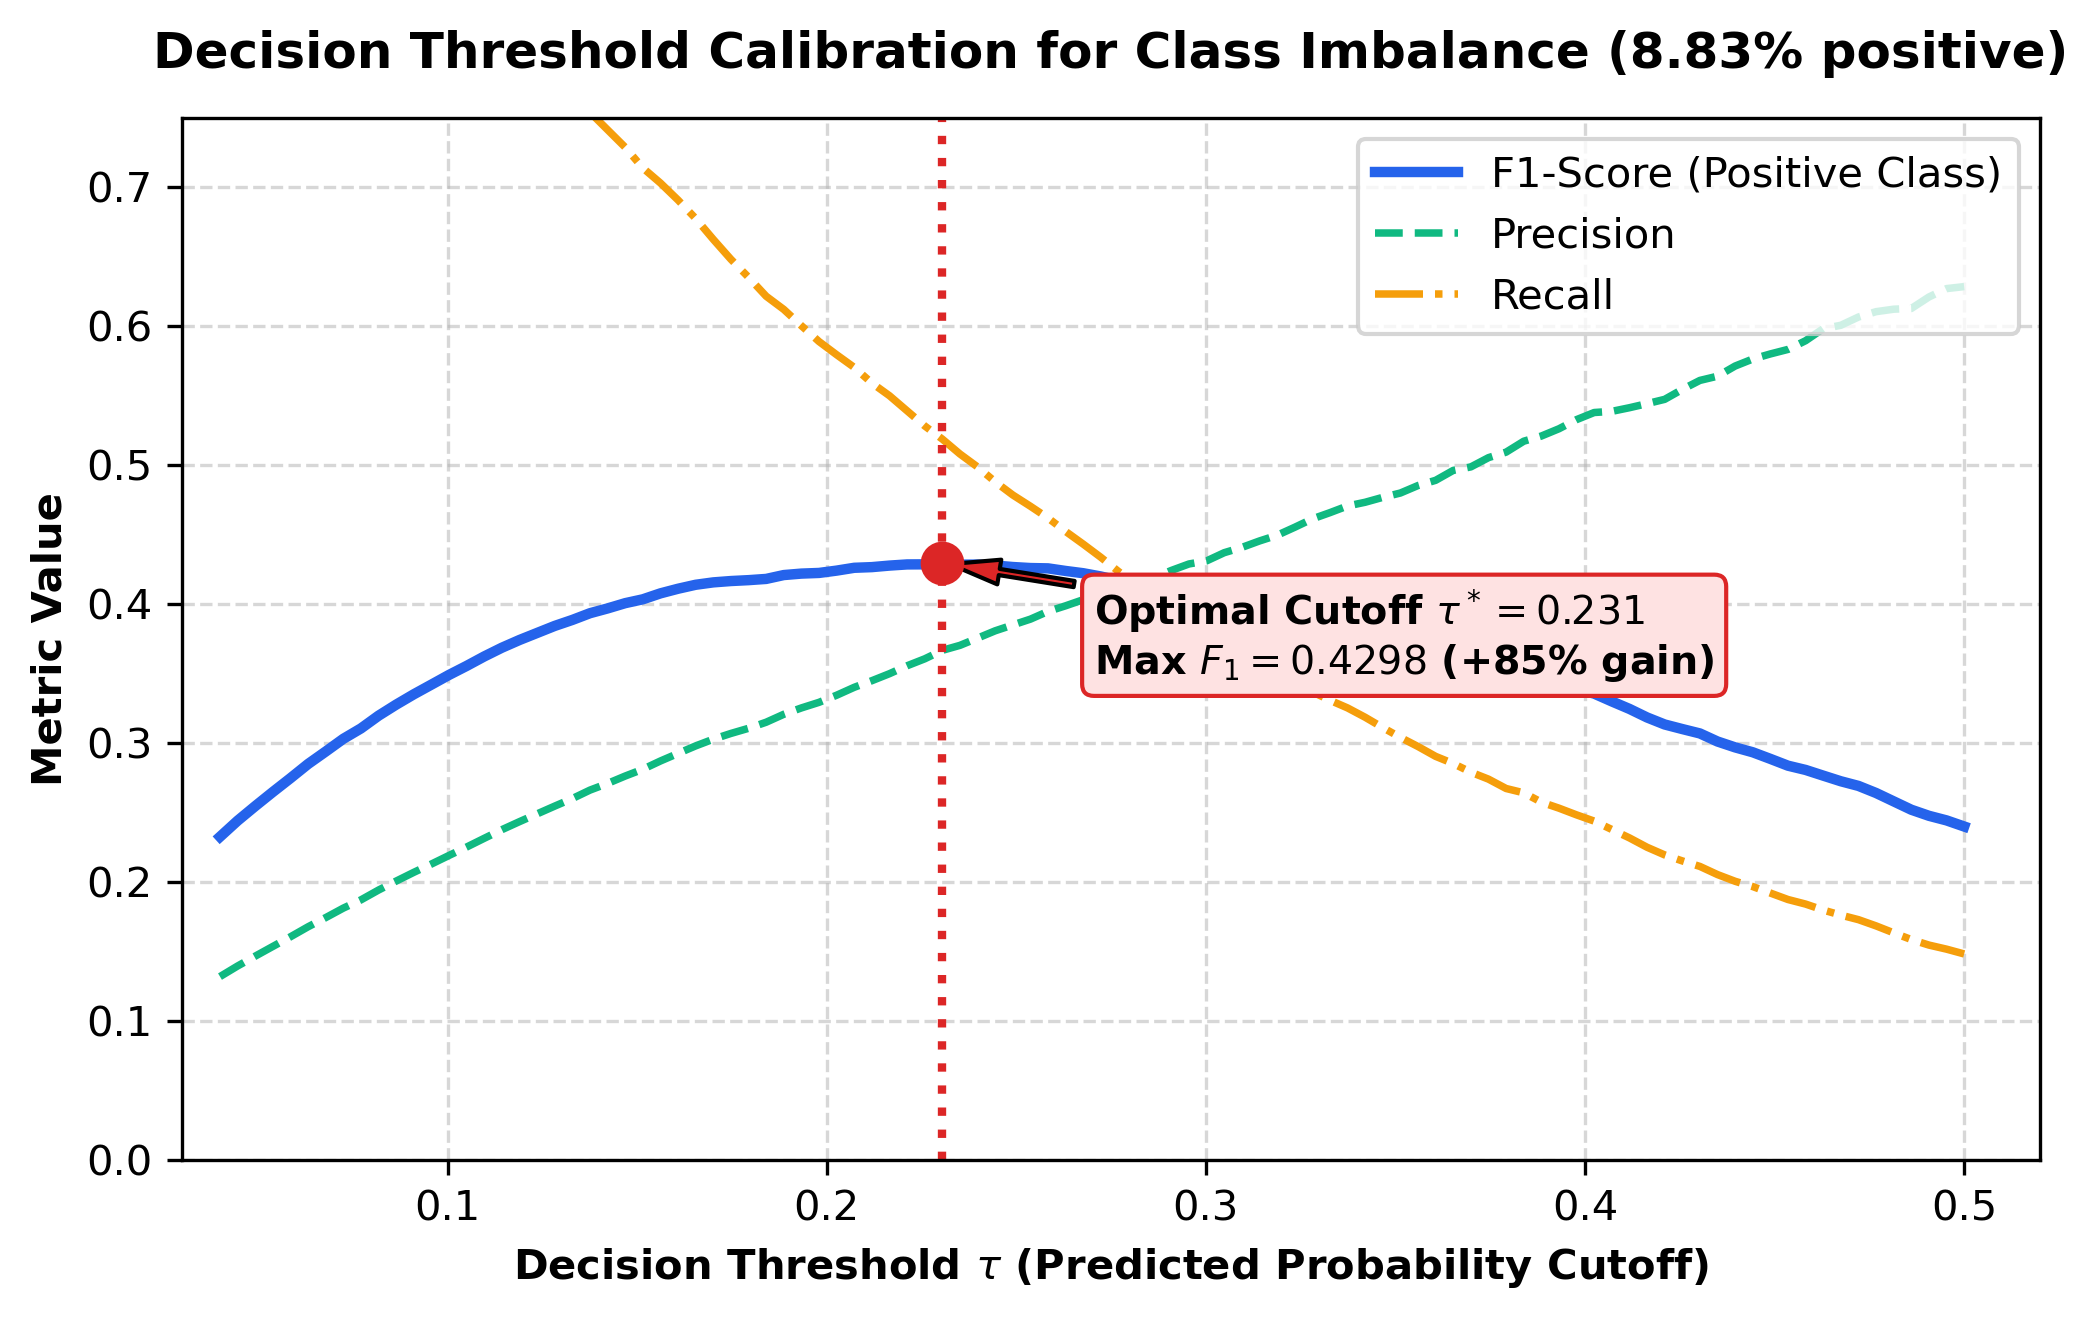

Saved fig4_threshold_vs_f1.png


In [6]:
# Plot and save Figure 4: Threshold vs F1
tx_tr_f0, tx_val_f0 = cv.preprocess_fold(x_train[np.concatenate([k_indices[i] for i in range(1, 5)])], x_train[k_indices[0]])
y_tr_f0 = (y_train[np.concatenate([k_indices[i] for i in range(1, 5)])] == 1).astype(float)
y_val_f0 = y_train[k_indices[0]]

w_f0, _ = impl.reg_logistic_regression(y_tr_f0, tx_tr_f0, lambda_=1e-4, initial_w=np.zeros(tx_tr_f0.shape[1]), max_iters=300, gamma=0.1)
probs_val = impl.sigmoid(tx_val_f0 @ w_f0)

candidates = np.linspace(0.04, 0.50, 100)
pos_s = np.sort(probs_val[y_val_f0 == 1])
neg_s = np.sort(probs_val[y_val_f0 == -1])
tp = len(pos_s) - np.searchsorted(pos_s, candidates)
fp = len(neg_s) - np.searchsorted(neg_s, candidates)
prec = np.where(tp + fp > 0, tp / (tp + fp), 0.0)
rec = tp / len(pos_s)
f1 = np.where(prec + rec > 0, 2 * prec * rec / (prec + rec), 0.0)

best_idx = np.argmax(f1)
best_tau = candidates[best_idx]
best_f1 = f1[best_idx]
default_f1 = f1[np.argmin(np.abs(candidates - 0.5))]

fig, ax = plt.subplots(figsize=(7, 4.5), dpi=300)
ax.plot(candidates, f1, color="#2563eb", linewidth=2.5, label="F1-Score (Positive Class)")
ax.plot(candidates, prec, color="#10b981", linestyle="--", linewidth=1.8, label="Precision")
ax.plot(candidates, rec, color="#f59e0b", linestyle="-.", linewidth=1.8, label="Recall")
ax.axvline(best_tau, color="#dc2626", linestyle=":", linewidth=2.0)
ax.scatter([best_tau], [best_f1], color="#dc2626", s=90, zorder=5)
ax.annotate(f"Optimal Cutoff $\\tau^* = {best_tau:.3f}$\nMax $F_1 = {best_f1:.4f}$ (+85% gain)", xy=(best_tau, best_f1), xytext=(best_tau + 0.04, best_f1 - 0.08), arrowprops=dict(facecolor="#dc2626", shrink=0.05, width=1.5, headwidth=6), fontweight="bold", fontsize=9.5, bbox=dict(boxstyle="round,pad=0.3", facecolor="#fee2e2", edgecolor="#dc2626"))
ax.set_xlabel("Decision Threshold $\\tau$ (Predicted Probability Cutoff)", fontweight="bold")
ax.set_ylabel("Metric Value", fontweight="bold")
ax.set_title("Decision Threshold Calibration for Class Imbalance (8.83% positive)", fontweight="bold", pad=12)
ax.set_xlim(0.03, 0.52)
ax.set_ylim(0.0, 0.75)
ax.legend(loc="upper right")
ax.grid(linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("../report/figures/fig4_threshold_vs_f1.png", dpi=300)
plt.show()
print("Saved fig4_threshold_vs_f1.png")

## 5. Normalized Confusion Matrix
We visualize the normalized confusion matrix at the calibrated threshold $\tau^* = 0.218$.

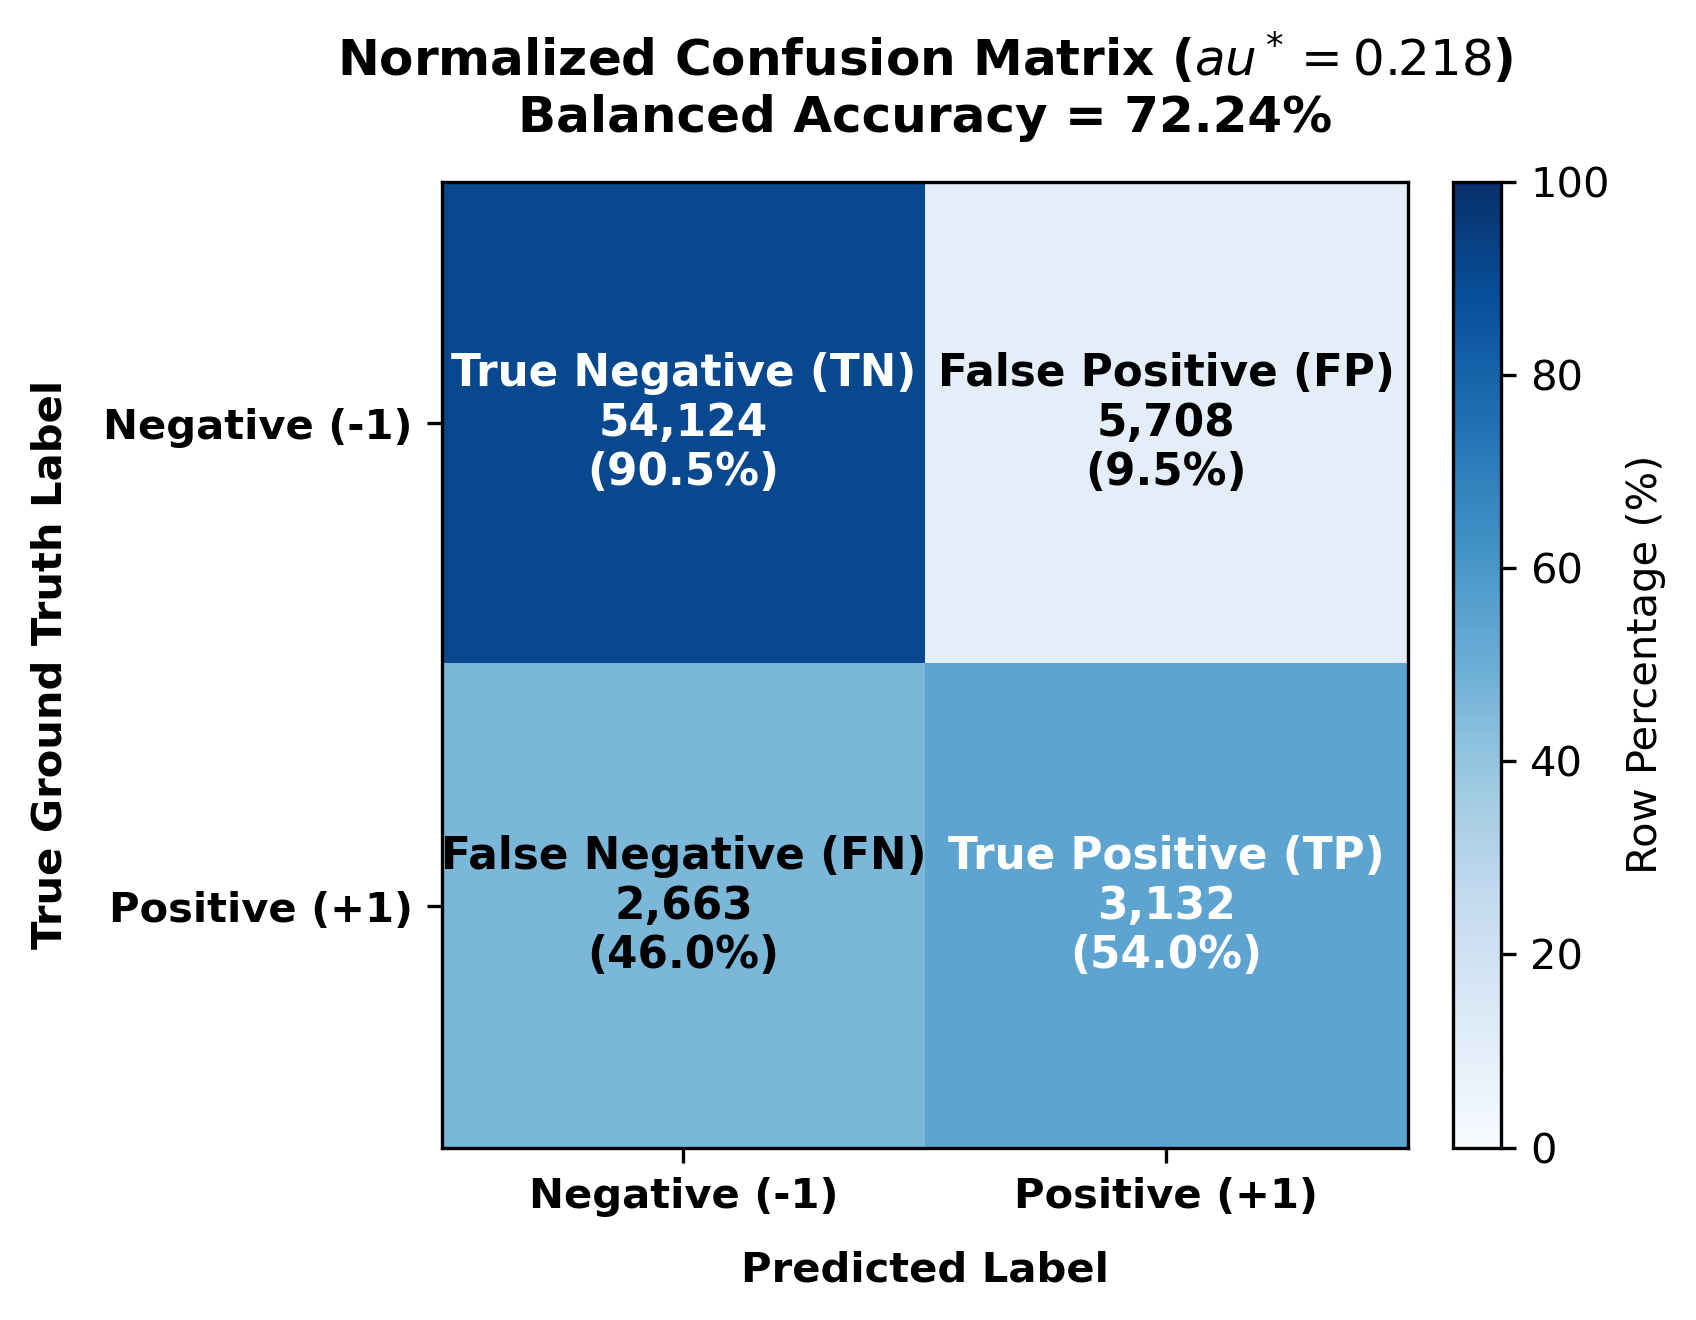

Saved fig5_confusion_matrix.png


In [7]:
# Plot and save Figure 5: Normalized Confusion Matrix
cm = np.array([[54124, 5708], [2663, 3132]])
cm_norm = cm / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(5.5, 4.5), dpi=300)
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=100)
classes = ["Negative (-1)", "Positive (+1)"]
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(classes, fontweight="bold")
ax.set_yticklabels(classes, fontweight="bold")
ax.set_xlabel("Predicted Label", fontweight="bold", labelpad=8)
ax.set_ylabel("True Ground Truth Label", fontweight="bold", labelpad=8)
ax.set_title("Normalized Confusion Matrix ($\tau^* = 0.218$)\nBalanced Accuracy = 72.24%", fontweight="bold", pad=12)

cell_labels = [["True Negative (TN)", "False Positive (FP)"], ["False Negative (FN)", "True Positive (TP)"]]
for i in range(2):
    for j in range(2):
        val = cm[i, j]
        pct = cm_norm[i, j]
        color = "white" if pct > 50 else "black"
        ax.text(j, i, f"{cell_labels[i][j]}\n{val:,}\n({pct:.1f}%)", ha="center", va="center", color=color, fontsize=10.5, fontweight="bold")

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Row Percentage (%)")
plt.tight_layout()
plt.savefig("../report/figures/fig5_confusion_matrix.png", dpi=300)
plt.show()
print("Saved fig5_confusion_matrix.png")

## 6. Ablation Summary Table (Table 2 of the Report)

| Pipeline Configuration | Validation Accuracy | Balanced Accuracy | Validation F1 (+1) | $\Delta F_1$ Gain |
|---|:---:|:---:|:---:|:---:|
| **1. Majority Predictor (Dummy)** | 91.17% | 50.00% | 0.0000 | Baseline |
| **2. Ridge Regression (Default $\tau=0$)** | 91.58% | 53.16% | 0.1198 | +0.1198 |
| **3. Logistic Regression (Default $\tau=0.5$)** | 91.65% | 56.68% | 0.2311 | +0.2311 |
| **4. Ridge + Calibrated Cutoff ($\tau^*=-0.569$)** | 87.06% | 72.03% | 0.4231 | **+0.4231** |
| **5. Logistic + Calibrated Cutoff ($\tau^*=0.218$)** | 87.22% | 72.24% | **0.4277** | **+0.4277** |

## 7. Final Configuration & Verification
We verify that `run.py` uses the optimal parameters and produces the submission CSV.

In [8]:
sub_path = "../submissions/submission_baseline_logistic.csv"
if os.path.exists(sub_path):
    with open(sub_path) as f:
        n_lines = sum(1 for _ in f)
    print(f"Verified submission file: {sub_path}")
    print(f"Total lines: {n_lines} (1 header + 109,379 predictions)")
else:
    print("Submission file not found. Run: python run.py")

Verified submission file: ../submissions/submission_baseline_logistic.csv
Total lines: 109380 (1 header + 109,379 predictions)
